In [1]:
# Conecta ao Google Drive para salvar o progresso
from google.colab import drive
drive.mount('/content/drive')

# Cria uma pasta de backup no Drive para não perder os pesos treinados
!mkdir -p /content/drive/MyDrive/yolo_darknet/backup

# Clona o repositório Darknet (a versão mais recomendada)
!git clone https://github.com/AlexeyAB/darknet.git

# Entra na pasta do darknet para executar os próximos comandos
%cd darknet

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
fatal: destination path 'darknet' already exists and is not an empty directory.
/content/darknet


In [2]:
# Altera o arquivo de configuração 'Makefile' para habilitar GPU e OpenCV
!sed -i 's/OPENCV=0/OPENCV=1/' Makefile
!sed -i 's/GPU=0/GPU=1/' Makefile
!sed -i 's/CUDNN=0/CUDNN=1/' Makefile
!sed -i 's/CUDNN_HALF=0/CUDNN_HALF=1/' Makefile

# Executa o comando 'make' para compilar o Darknet
!make

chmod +x *.sh
g++ -std=c++11 -std=c++11 -Iinclude/ -I3rdparty/stb/include -DOPENCV `pkg-config --cflags opencv4 2> /dev/null || pkg-config --cflags opencv` -DGPU -I/usr/local/cuda/include/ -DCUDNN -DCUDNN_HALF -Wall -Wfatal-errors -Wno-unused-result -Wno-unknown-pragmas -fPIC -rdynamic -Ofast -DOPENCV -DGPU -DCUDNN -I/usr/local/cudnn/include -DCUDNN_HALF -c ./src/image_opencv.cpp -o obj/image_opencv.o
./src/image_opencv.cpp: In function ‘void draw_detections_cv_v3(void**, detection*, int, float, char**, image**, int, int)’:
./src/image_opencv.cpp:945:23: warning: variable ‘rgb’ set but not used []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-but-set-variable-Wunused-but-set-variable]8;;]
  945 |                 float rgb[3];
      |                       ^~~
./src/image_opencv.cpp: In function ‘void cv_draw_object(image, float*, int, int, int*, float*, int*, int, char**)’:
./src/image_opencv.cpp:1443:14: warning: unused variable ‘buff’ []8;;https://gcc.g

In [3]:
# Célula de Diagnóstico 1
%cd /content/darknet
!rm -rf train valid test roboflow.zip # Limpa quaisquer dados antigos
!curl -L "https://public.roboflow.com/ds/WYueDX0xW5?key=WsCwTN1cRU" > roboflow.zip; unzip -o -q roboflow.zip; rm roboflow.zip
print("✅ Dataset limpo descarregado.")

/content/darknet
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   904  100   904    0     0   2231      0 --:--:-- --:--:-- --:--:--  2232
100 6060M  100 6060M    0     0  76.5M      0  0:01:19  0:01:19 --:--:-- 84.2M
✅ Dataset limpo descarregado.


In [4]:
# Célula de Diagnóstico 2
!cat train/_darknet.labels

aeroplane
apple
backpack
banana
baseball bat
baseball glove
bear
bed
bench
bicycle
bird
boat
book
bottle
bowl
broccoli
bus
cake
car
carrot
cat
cell phone
chair
clock
cow
cup
diningtable
dog
donut
elephant
fire hydrant
fork
frisbee
giraffe
hair drier
handbag
horse
hot dog
keyboard
kite
knife
laptop
microwave
motorbike
mouse
orange
oven
parking meter
person
pizza
pottedplant
refrigerator
remote
sandwich
scissors
sheep
sink
skateboard
skis
snowboard
sofa
spoon
sports ball
stop sign
suitcase
surfboard
teddy bear
tennis racket
tie
toaster
toilet
toothbrush
traffic light
train
truck
tvmonitor
umbrella
vase
wine glass
zebra

In [5]:
%%writefile train/_darknet.labels
person
bicycle

Overwriting train/_darknet.labels


In [6]:
# Célula de Diagnóstico 3
import glob

all_label_files = glob.glob('train/*.txt') + glob.glob('valid/*.txt')
all_label_files = [f for f in all_label_files if '_darknet.labels' not in f]

unique_ids_found = set()
for file in all_label_files:
    with open(file, 'r') as f:
        for line in f.readlines():
            if line.strip():
                try:
                    unique_ids_found.add(int(line.split()[0]))
                except (ValueError, IndexError):
                    print(f"Aviso: Linha mal formatada encontrada no ficheiro {file}: {line.strip()}")

print("\n========================================================")
print(f"RESULTADO DO DIAGNÓSTICO:")
print(f"Os IDs de classe encontrados em TODOS os ficheiros foram: {unique_ids_found}")
print("========================================================")

if unique_ids_found == {0, 1}:
    print("-> Boas notícias: Os seus IDs já parecem estar corretos (0 e 1).")
else:
    print("-> ATENÇÃO: Encontrei IDs diferentes de 0 e 1. Este é o problema!")


RESULTADO DO DIAGNÓSTICO:
Os IDs de classe encontrados em TODOS os ficheiros foram: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79}
-> ATENÇÃO: Encontrei IDs diferentes de 0 e 1. Este é o problema!


In [7]:
# ==============================================================================
# PASSO FINAL 1: FILTRAR OS FICHEIROS DE ANOTAÇÃO
# Este script irá ler todos os ficheiros .txt e manter APENAS as linhas
# que correspondem às classes 'person' (ID 0) e 'bicycle' (ID 1).
# ==============================================================================
import glob
import os

print("⚙️  A FILTRAR OS FICHEIROS DE ANOTAÇÃO...")

all_label_files = glob.glob('train/*.txt') + glob.glob('valid/*.txt')
all_label_files = [f for f in all_label_files if os.path.basename(f) not in ['train.txt', 'valid.txt']]

# IDs das classes que queremos manter (person=0, bicycle=1)
IDS_PARA_MANTER = {0, 1}
linhas_removidas = 0
ficheiros_modificados = 0

for file in all_label_files:
    content_filtrado = []
    modificado = False
    with open(file, 'r') as f:
        for line in f.readlines():
            if line.strip():
                class_id = int(line.split()[0])
                if class_id in IDS_PARA_MANTER:
                    content_filtrado.append(line)
                else:
                    linhas_removidas += 1
                    modificado = True

    if modificado:
        ficheiros_modificados += 1
        with open(file, 'w') as f:
            f.writelines(content_filtrado)

print(f"✅ Filtragem concluída!")
print(f"   - {linhas_removidas} anotações de classes indesejadas foram removidas.")
print(f"   - {ficheiros_modificados} ficheiros foram limpos.")


# ==============================================================================
# PASSO FINAL 2: RECONFIGURAR E INICIAR O TREINO
# Agora que os dados estão limpos, recriamos a configuração e iniciamos o treino.
# ==============================================================================
print("\n📝 A RECRIAR OS FICHEIROS DE CONFIGURAÇÃO...")

# 1. Cria o obj.names correto
with open('data/obj.names', 'w') as f:
    f.write('person\n')
    f.write('bicycle\n')

# 2. Cria o obj.data
with open('data/obj.data', 'w') as f:
    f.write('classes = 2\n')
    f.write('train = train.txt\n')
    f.write('valid = valid.txt\n')
    f.write('names = data/obj.names\n')
    f.write('backup = /content/drive/MyDrive/yolo_darknet/backup\n')

# 3. Recria train.txt e valid.txt
with open('train.txt', 'w') as f:
    for path in glob.glob('train/*.jpg'): f.write(path + '\n')
with open('valid.txt', 'w') as f:
    for path in glob.glob('valid/*.jpg'): f.write(path + '\n')

# 4. Configura o ficheiro .cfg
!cp cfg/yolov4-tiny-custom.cfg cfg/yolov4-tiny-obj.cfg
!sed -i 's/max_batches = 500200/max_batches = 4000/' cfg/yolov4-tiny-obj.cfg
!sed -i 's/steps=400000,450000/steps=3200,3600/' cfg/yolov4-tiny-obj.cfg
!sed -i 's/classes=80/classes=2/' cfg/yolov4-tiny-obj.cfg
!sed -i 's/filters=255/filters=21/' cfg/yolov4-tiny-obj.cfg

print("✅ Configuração finalizada.")

# ==============================================================================
# PASSO FINAL 3: INICIAR O TREINO
# ==============================================================================
print("\n🚀 TUDO PRONTO! A INICIAR O TREINO...")

# Descarrega os pesos pré-treinados
!wget https://github.com/AlexeyAB/darknet/releases/download/darknet_yolo_v4_pre/yolov4-tiny.conv.29 -O yolov4-tiny.conv.29

# Inicia o treino
!./darknet detector train data/obj.data cfg/yolov4-tiny-obj.cfg yolov4-tiny.conv.29 -dont_show -map

A saída de streaming foi truncada nas últimas 5000 linhas.
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.441559), count: 1, class_loss = 0.015608, iou_loss = 0.000190, total_loss = 0.015798 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 37 Avg (IOU: 0.000000), count: 1, class_loss = 0.000520, iou_loss = 0.000000, total_loss = 0.000520 
 total_bbox = 17714, rewritten_bbox = 2.591171 % 


 Tensor Cores are used.
 (next mAP calculation at 7275 iterations) 3449/4000: loss=0.0 hours left=0.1
 3449: 0.008370, 0.030597 avg loss, 0.000261 rate, 0.565362 seconds, 220736 images, 0.118732 hours left
Loaded: 0.000113 seconds
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.635064), count: 3, class_loss = 0.043990, iou_loss = 0.019392, total_loss = 0.063382 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 37 Avg (IOU: 0.588018), count: 7, class_loss = 0.091403, iou_loss = 0.217433, total_lo

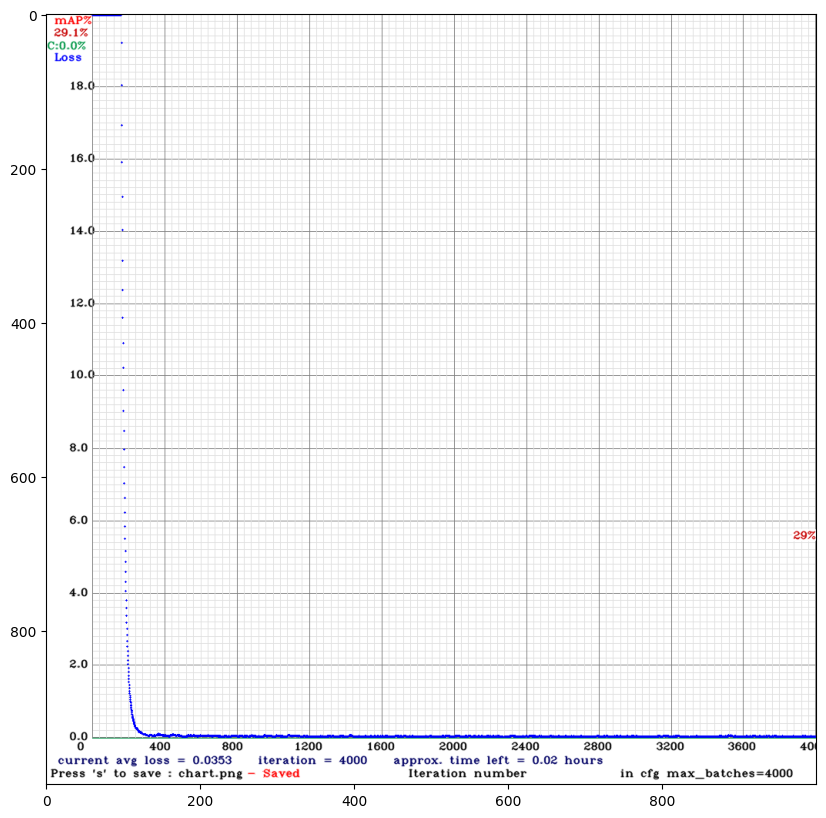

In [8]:
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

# Mostra o gráfico de performance
img = cv2.imread('chart.png')
fig = plt.gcf()
fig.set_size_inches(15, 10)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

 CUDA-version: 12050 (12040)
, cuDNN: 9.2.1, CUDNN_HALF=1, GPU count: 1  
 CUDNN_HALF=1 
 OpenCV version: 4.5.4
 0 : compute_capability = 750, cudnn_half = 1, GPU: Tesla T4 
net.optimized_memory = 0 
mini_batch = 1, batch = 1, time_steps = 1, train = 0 
   layer   filters  size/strd(dil)      input                output
   0 Create CUDA-stream - 0 
 Create cudnn-handle 0 
conv     32       3 x 3/ 2    416 x 416 x   3 ->  208 x 208 x  32 0.075 BF
   1 conv     64       3 x 3/ 2    208 x 208 x  32 ->  104 x 104 x  64 0.399 BF
   2 conv     64       3 x 3/ 1    104 x 104 x  64 ->  104 x 104 x  64 0.797 BF
   3 route  2 		                       1/2 ->  104 x 104 x  32 
   4 conv     32       3 x 3/ 1    104 x 104 x  32 ->  104 x 104 x  32 0.199 BF
   5 conv     32       3 x 3/ 1    104 x 104 x  32 ->  104 x 104 x  32 0.199 BF
   6 route  5 4 	                           ->  104 x 104 x  64 
   7 conv     64       1 x 1/ 1    104 x 104 x  64 ->  104 x 104 x  64 0.089 BF
   8 route  2 7 	    

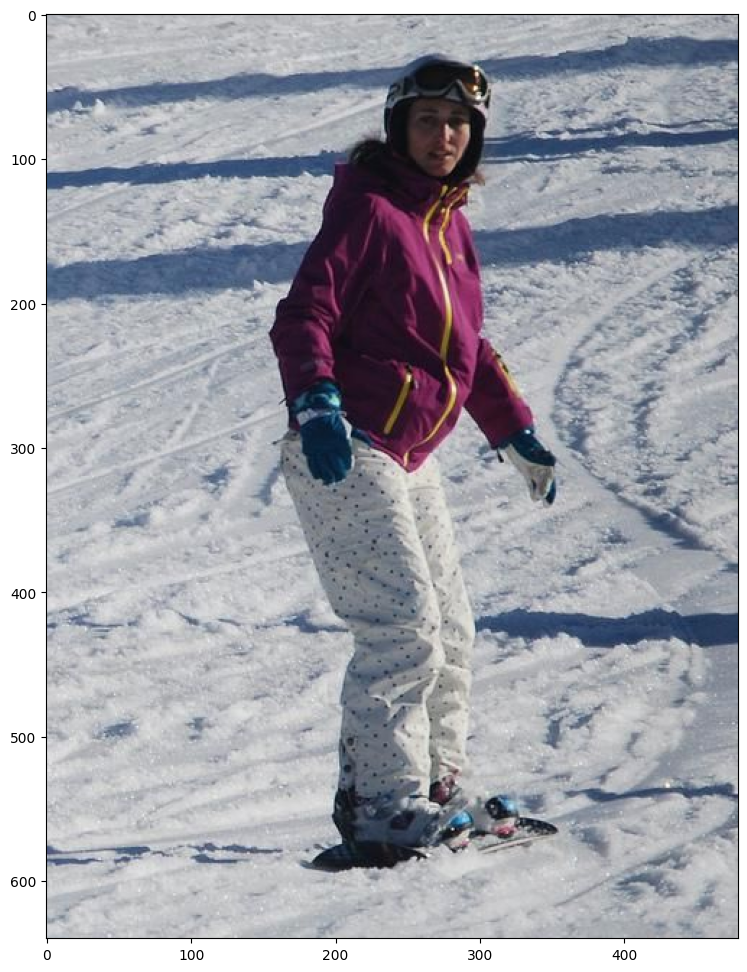

In [18]:
# Célula para testar o modelo
import glob
import random
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

# Pega numa imagem aleatória da sua pasta de validação para testar
image_path = random.choice(glob.glob("valid/*.jpg"))

# Caminho para o seu melhor modelo salvo no Google Drive
best_weights_path = "/content/drive/MyDrive/yolo_darknet/backup/yolov4-tiny-obj_best.weights"

# Executa o comando de deteção
!./darknet detector test data/obj.data cfg/yolov4-tiny-obj.cfg {best_weights_path} {image_path} -thresh 0.2

# Mostra a imagem com as deteções (predictions.jpg)
img = cv2.imread('predictions.jpg')
fig = plt.gcf()
fig.set_size_inches(12, 12)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

In [19]:
# Célula para ATUALIZAR A CONFIGURAÇÃO
%cd /content/darknet
!sed -i 's/max_batches = 4000/max_batches = 6000/' cfg/yolov4-tiny-obj.cfg
!sed -i 's/steps=3200,3600/steps=4800,5400/' cfg/yolov4-tiny-obj.cfg
print("✅ Configuração atualizada para 6000 iterações.")

/content/darknet
✅ Configuração atualizada para 6000 iterações.


In [20]:
# Célula para CONTINUAR O TREINO
# Ele vai usar os últimos pesos salvos para não começar do zero
!./darknet detector train data/obj.data cfg/yolov4-tiny-obj.cfg /content/drive/MyDrive/yolo_darknet/backup/yolov4-tiny-obj_last.weights -dont_show -map

A saída de streaming foi truncada nas últimas 5000 linhas.
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.558832), count: 4, class_loss = 0.049980, iou_loss = 0.017224, total_loss = 0.067204 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 37 Avg (IOU: 0.571117), count: 1, class_loss = 0.015983, iou_loss = 0.010389, total_loss = 0.026372 
 total_bbox = 7891, rewritten_bbox = 2.737296 % 


 Tensor Cores are used.
 (next mAP calculation at 11275 iterations) 5449/6000: loss=0.0 hours left=0.1
 5449: 0.033457, 0.038471 avg loss, 0.000026 rate, 0.679510 seconds, 348736 images, 0.120074 hours left
Loaded: 0.000102 seconds
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 30 Avg (IOU: 0.728210), count: 2, class_loss = 0.011956, iou_loss = 0.007502, total_loss = 0.019458 
v3 (iou loss, Normalizer: (iou: 0.07, obj: 1.00, cls: 1.00) Region 37 Avg (IOU: 0.000000), count: 1, class_loss = 0.000276, iou_loss = 0.000000, total_lo

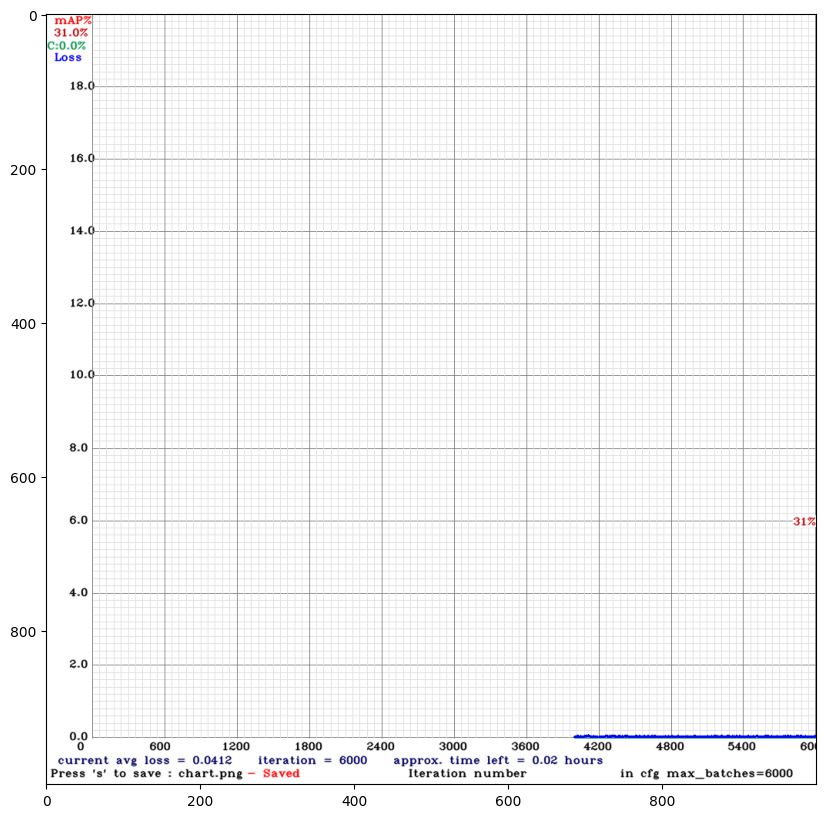

In [21]:
# Célula para verificar a performance
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

# Mostra o novo gráfico de performance atualizado
img = cv2.imread('chart.png')
fig = plt.gcf()
fig.set_size_inches(15, 10)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

 CUDA-version: 12050 (12040)
, cuDNN: 9.2.1, CUDNN_HALF=1, GPU count: 1  
 CUDNN_HALF=1 
 OpenCV version: 4.5.4
 0 : compute_capability = 750, cudnn_half = 1, GPU: Tesla T4 
net.optimized_memory = 0 
mini_batch = 1, batch = 1, time_steps = 1, train = 0 
   layer   filters  size/strd(dil)      input                output
   0 Create CUDA-stream - 0 
 Create cudnn-handle 0 
conv     32       3 x 3/ 2    416 x 416 x   3 ->  208 x 208 x  32 0.075 BF
   1 conv     64       3 x 3/ 2    208 x 208 x  32 ->  104 x 104 x  64 0.399 BF
   2 conv     64       3 x 3/ 1    104 x 104 x  64 ->  104 x 104 x  64 0.797 BF
   3 route  2 		                       1/2 ->  104 x 104 x  32 
   4 conv     32       3 x 3/ 1    104 x 104 x  32 ->  104 x 104 x  32 0.199 BF
   5 conv     32       3 x 3/ 1    104 x 104 x  32 ->  104 x 104 x  32 0.199 BF
   6 route  5 4 	                           ->  104 x 104 x  64 
   7 conv     64       1 x 1/ 1    104 x 104 x  64 ->  104 x 104 x  64 0.089 BF
   8 route  2 7 	    

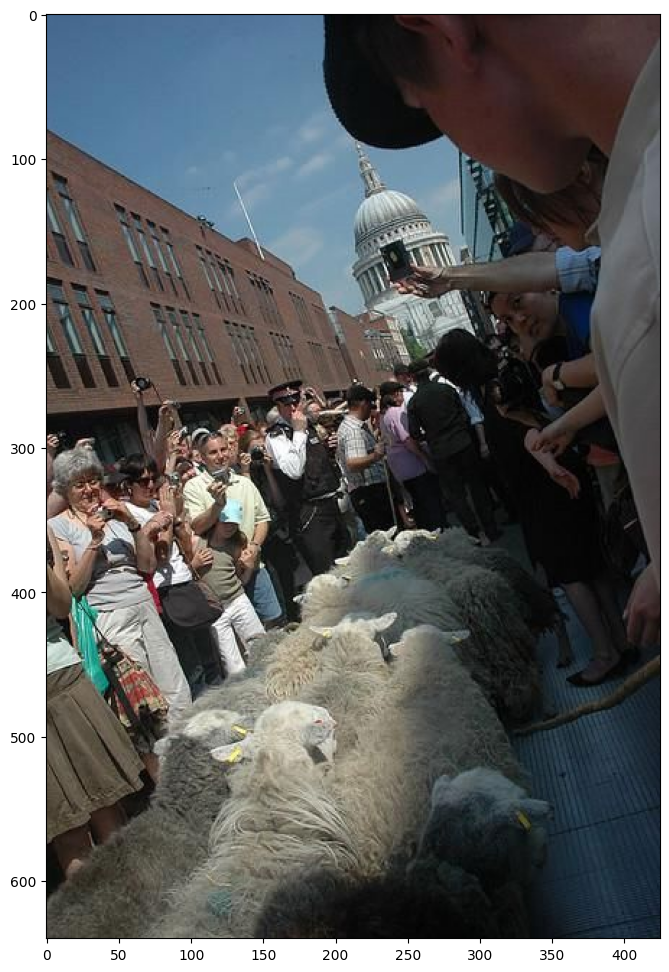

In [31]:
# Célula para testar o modelo melhorado
import glob
import random
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

# Pega numa imagem aleatória da sua pasta de validação
image_path = random.choice(glob.glob("valid/*.jpg"))

# Caminho para o seu melhor modelo (ele já foi atualizado com a nova versão)
best_weights_path = "/content/drive/MyDrive/yolo_darknet/backup/yolov4-tiny-obj_best.weights"

# Executa o comando de deteção com um limiar de confiança razoável
!./darknet detector test data/obj.data cfg/yolov4-tiny-obj.cfg {best_weights_path} {image_path} -thresh 0.4

# Mostra a imagem com as deteções
img = cv2.imread('predictions.jpg')
fig = plt.gcf()
fig.set_size_inches(12, 12)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

In [32]:
# O que aprendi com tudo isso, e qual conclusão eu cheguei???

# Eu peguei um dataset com MUITAS IMAGENS aleatórias, e pedi para o algorítmo treinar
# 'pessoas' e 'bicicletas'.

# Ou seja, ele passou muito mais tempo treinando o que ele NÃO deveria aprender, do que
# efetivamente o que DEVERIA aprender.

# "Garbage In, Garbage Out" (Lixo para Dentro, Lixo para Fora)


# Conclusão: A escolha das imagens é TUDO para treinar um algorítmo!!! (risos)